# Base A - Calidad de datos

Esta notebook audita exclusivamente los artefactos ya generados de Base A. No llama APIs, no modifica datasets, no imputa faltantes, no elimina outliers, no resamplea y no realiza reconciliaciones entre series.


## 1. Carga de configuración y artefactos existentes

Se detecta la raíz del repositorio a partir de la carpeta `data_a`. Todos los archivos se leen como insumos; ninguna celda escribe sobre ellos.


In [1]:
from pathlib import Path
import holidays
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas.tseries.offsets import CustomBusinessDay

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)
plt.style.use("seaborn-v0_8-whitegrid")


# Calendario bancario BCRA
# Fuente oficial: https://www.bcra.gob.ar/consulta-feriados-bancarios/
#
# Se parte del calendario de feriados nacionales de Argentina y se agregan
# cierres/no laborables bancarios documentados por BCRA que pueden no estar
# presentes en un calendario civil genérico.
#
# El archivo histórico online del BCRA cubre 2011 en adelante. Para años
# anteriores se utiliza el calendario nacional + Día del Bancario.

BCRA_BANK_HOLIDAY_EXTRAS = {
    # 2011
    "2011-03-25", "2011-04-21", "2011-12-09",
    # 2012
    "2012-04-05", "2012-12-24",
    # 2013
    "2013-01-31", "2013-02-20", "2013-03-28", "2013-04-01", "2013-06-21",
    # 2014
    "2014-04-17", "2014-05-02", "2014-12-26",
    # 2015
    "2015-03-23", "2015-12-07",
    # 2016
    "2016-07-08", "2016-12-09",
    # 2017
    "2017-04-13",
    # 2018
    "2018-03-29", "2018-04-30", "2018-11-30", "2018-12-18", "2018-12-31",
    # 2019
    "2019-04-18", "2019-07-08", "2019-08-19", "2019-10-14",
    # 2020
    "2020-03-23", "2020-07-10", "2020-12-07", "2020-12-31",
    # 2021
    "2021-04-01", "2021-05-24", "2021-10-08", "2021-11-22",
    # 2022
    "2022-04-14", "2022-05-18", "2022-10-07", "2022-11-21", "2022-12-09",
    # 2023
    "2023-04-06", "2023-05-26", "2023-06-19", "2023-10-13",
    # 2024
    "2024-04-01", "2024-06-21", "2024-10-11",
    # 2025
    "2025-04-17", "2025-05-02", "2025-08-15", "2025-11-21",
    # 2026
    "2026-03-23", "2026-07-10", "2026-12-07",
}
BCRA_BANK_HOLIDAY_EXTRAS = {
    pd.Timestamp(value).normalize() for value in BCRA_BANK_HOLIDAY_EXTRAS
}


def bcra_bank_holidays(start, end):
    start = pd.Timestamp(start).normalize()
    end = pd.Timestamp(end).normalize()

    if pd.isna(start) or pd.isna(end) or start > end:
        return pd.DatetimeIndex([])

    years = range(start.year, end.year + 1)

    # Feriados nacionales/trasladables de Argentina.
    national_holidays = holidays.country_holidays("AR", years=years)
    holiday_dates = {
        pd.Timestamp(value).normalize()
        for value in national_holidays.keys()
    }

    # Cierres bancarios adicionales documentados por BCRA.
    holiday_dates |= {
        value for value in BCRA_BANK_HOLIDAY_EXTRAS
        if start <= value <= end
    }

    # Día del Bancario: las sucursales no operan el 6 de noviembre.
    holiday_dates |= {
        pd.Timestamp(year=year, month=11, day=6)
        for year in years
    }

    return pd.DatetimeIndex(sorted(
        value for value in holiday_dates
        if start <= value <= end
    ))


def bcra_bank_business_days(start, end):
    start = pd.Timestamp(start).normalize()
    end = pd.Timestamp(end).normalize()

    if pd.isna(start) or pd.isna(end) or start > end:
        return pd.DatetimeIndex([])

    bank_holidays = bcra_bank_holidays(start, end)
    business_day = CustomBusinessDay(holidays=list(bank_holidays))

    return pd.date_range(start, end, freq=business_day)


EXPECTED_IDS = {
    # Tipo de Titular:
    # Personas humanas, Prestadores de Servicios Financieros, PyMes, no Pymes

    # Hipotecario / Destino:
    # Construcción, Refacción, Compra vivienda nueva, Compra vivienda usada, Otras operaciones.

    # Prestamos Generales
    883, 885, 891, 892,
    # Hipotecarios por tipo de titular:
    # ML:
    927, 929, 935, 936, 
    # ME: 
    938, 940, 946, 947,
    # Hipotecarios por destino:
    # Personas humanas:
    # ML:
    1145, 1146, 1147, 1148, 1149,
    # ME:
    1153, 1154, 1155, 1156, 1157,
    # Personas jurídicas:
    # ML:
    1169, 1170, 1171, 1172, 1173,
    # ME:
    1177, 1178, 1179, 1180, 1181,

    # Prendarios por tipo de titular:
    # ML:
    960, 962, 968, 969,
    # ME:
    971, 973, 979, 980,
    # Prendarios por destino
    # automotores, maquinarias, otros
    # Personas humanas - ML
    1150, 1151, 1152,
    # Personas humanas - ME
    1158, 1159, 1160,
    # Personas jurídicas - ML
    1174, 1175, 1176,
    # Personas jurídicas - ME
    1182, 1183, 1184,

    # Tasas de crédito a personas
    14,    # Préstamos personales - diaria
    1215,  # Financiaciones con tarjetas de crédito - mensual
    1220,  # Tarjetas de crédito con tasa distinta de cero - mensual
    1218,  # Préstamos prendarios a tasa fija - mensual
    1240,  # Préstamos hipotecarios UVA - mensual

    # Tasas de crédito a empresas / actividad comercial
    1199,  # Adelantos en cuenta corriente a tasa fija - mensual
    1216,  # Documentos a sola firma a tasa fija - mensual
    145,   # Adelantos en cuenta corriente a empresas privadas, 1-7 días, >=10M - diaria

    # Tasas de referencia / fondeo  
    7,     # BADLAR bancos privados - diaria
    135,   # TAMAR bancos públicos y privados - diaria
    1189,  # Depósitos a plazo fijo en pesos - diaria

    27,   # Inflación mensual - mensual
    28,   # Inflación interanual - mensual

}
EXPECTED_HISTORY_COLUMNS = {
    "idVariable", "nombre_corto", "fecha", "valor", "descripcion",
    "categoria", "periodicidad", "unidadExpresion", "moneda",
}
EXPECTED_METADATA_COLUMNS = {
    "idVariable", "nombre_corto", "descripcion", "categoria",
    "periodicidad", "unidadExpresion", "moneda",
}

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((path for path in candidates if (path / "data_a").is_dir()), Path.cwd())
DATA_A = ROOT / "data_a"
PATHS = {
    "history": DATA_A / "processed" / "bcra_monetarias_history_long.csv",
    "divisas": DATA_A / "processed" / "bcra_divisas.csv",
    "cotizaciones": DATA_A / "processed" / "bcra_cotizaciones_snapshot.csv",
    "usd_history": DATA_A / "processed" / "bcra_usd_history.csv",
    "catalog": DATA_A / "metadata" / "bcra_monetarias_catalog.csv",
    "selected_catalog": DATA_A / "metadata" / "bcra_monetarias_selected_catalog.csv",
    "methodology": DATA_A / "metadata" / "bcra_monetarias_metodologia.csv",
    "summary": DATA_A / "logs" / "bcra_api_test_summary.csv",
}

file_inventory = pd.DataFrame([
    {"artefacto": name, "ruta": str(path), "existe": path.is_file(), "bytes": path.stat().st_size if path.is_file() else None}
    for name, path in PATHS.items()
])
file_inventory


,artefacto,ruta,existe,bytes
0,history,c:\Users\Asus\OneDrive\BRIAN\CAECE\4°año_2°Cua...,True,7102761
1,divisas,c:\Users\Asus\OneDrive\BRIAN\CAECE\4°año_2°Cua...,True,865
2,cotizaciones,c:\Users\Asus\OneDrive\BRIAN\CAECE\4°año_2°Cua...,True,1950
3,usd_history,c:\Users\Asus\OneDrive\BRIAN\CAECE\4°año_2°Cua...,True,131
4,catalog,c:\Users\Asus\OneDrive\BRIAN\CAECE\4°año_2°Cua...,True,265941
5,selected_catalog,c:\Users\Asus\OneDrive\BRIAN\CAECE\4°año_2°Cua...,True,14061
6,methodology,c:\Users\Asus\OneDrive\BRIAN\CAECE\4°año_2°Cua...,True,34241
7,summary,c:\Users\Asus\OneDrive\BRIAN\CAECE\4°año_2°Cua...,True,14769


BADLAR y TAMAR son tasas de referencia del sistema financiero argentino, construidas a partir de depósitos a plazo fijo.

BADLAR: tasa promedio que pagan los bancos por depósitos a plazo fijo de gran monto. Históricamente se usa mucho como referencia de fondeo bancario.

TAMAR: una referencia más nueva del BCRA para depósitos a plazo fijo en pesos, pensada para reflejar mejor el costo de fondeo actual del sistema.


In [2]:
missing_required = file_inventory.loc[~file_inventory["existe"], "artefacto"].tolist()
if missing_required:
    raise FileNotFoundError(f"Faltan artefactos requeridos: {missing_required}")

history_raw = pd.read_csv(PATHS["history"])
catalog = pd.read_csv(PATHS["catalog"])
selected_catalog = pd.read_csv(PATHS["selected_catalog"])
methodology = pd.read_csv(PATHS["methodology"])
api_summary = pd.read_csv(PATHS["summary"])

history = history_raw.copy()
history["idVariable_num"] = pd.to_numeric(history["idVariable"], errors="coerce")
history["fecha_dt"] = pd.to_datetime(history["fecha"], errors="coerce")
history["valor_num"] = pd.to_numeric(history["valor"], errors="coerce")

catalog["idVariable"] = pd.to_numeric(catalog["idVariable"], errors="coerce").astype("Int64")
selected_catalog["idVariable"] = pd.to_numeric(selected_catalog["idVariable"], errors="coerce").astype("Int64")
selected_catalog.head()


,idVariable,nombre_corto,descripcion,categoria,tipoSerie,periodicidad,unidadExpresion,moneda,primerFechaInformada,ultFechaInformada,ultValorInformado
0,7,tasa_badlar_privados,Tasa de interés BADLAR de bancos privados,Principales Variables,Tasa de interés,D,En porcentaje nominal anual,ML,1999-01-04,2026-09-10,22.3125
1,14,tasa_prestamos_personales,Tasa de interés de préstamos personales,Principales Variables,Tasa de interés,D,En porcentaje nominal anual,ML,2010-07-01,2026-09-10,63.4600
2,27,inflacion_mensual,Inflación mensual.,Principales Variables,Variación,M,En porcentaje,ML,1943-03-31,2026-08-31,1.7000
3,28,inflacion_interanual,Inflación interanual.,Principales Variables,Variación,M,En porcentaje,ML,1944-01-31,2026-08-31,33.5000
4,135,tasa_tamar,Tasa de interés TAMAR de bancos públicos y pri...,Series.xlsm,Tasa de interés,D,En porcentaje nominal anual,ML,2024-10-01,2026-09-10,23.0000


## 2. Inventario e integridad estructural

Este bloque verifica presencia, ausencia, duplicación, columnas, tipos y conversiones sin corregir los datos.


In [3]:
present_ids = set(pd.to_numeric(history_raw["idVariable"], errors="coerce").dropna().astype(int))
expected_inventory = pd.DataFrame({
    "idVariable": sorted(EXPECTED_IDS),
})
expected_inventory["presente_en_historico"] = expected_inventory["idVariable"].isin(present_ids)
counts_by_id = pd.to_numeric(history_raw["idVariable"], errors="coerce").value_counts()
expected_inventory["n_observaciones"] = expected_inventory["idVariable"].map(counts_by_id).fillna(0).astype(int)
expected_inventory["serie_vacia"] = expected_inventory["n_observaciones"].eq(0)

unexpected_ids = sorted(present_ids - EXPECTED_IDS)
summary_ok = api_summary["ok"].astype(str).str.strip().str.lower().eq("true")
extraction_failures = api_summary.loc[
    api_summary["test"].str.endswith("_historico", na=False) & ~summary_ok
].copy()

print("Series esperadas:", len(EXPECTED_IDS))
print("Series presentes:", len(present_ids))
print("Series inesperadas:", unexpected_ids)
expected_inventory


Series esperadas: 65
Series presentes: 65
Series inesperadas: []


,idVariable,presente_en_historico,n_observaciones,serie_vacia
0,7,True,6758,False
1,14,True,3940,False
2,27,True,1002,False
3,28,True,992,False
4,135,True,468,False
5,145,True,4308,False
6,883,True,319,False
7,885,True,319,False
8,891,True,319,False
9,892,True,319,False


In [4]:
column_inventory = pd.DataFrame([
    {
        "dataset": "bcra_monetarias_history_long",
        "columnas_esperadas_faltantes": sorted(EXPECTED_HISTORY_COLUMNS - set(history_raw.columns)),
        "columnas_inesperadas": sorted(set(history_raw.columns) - EXPECTED_HISTORY_COLUMNS),
    },
    {
        "dataset": "bcra_monetarias_selected_catalog",
        "columnas_esperadas_faltantes": sorted(EXPECTED_METADATA_COLUMNS - set(selected_catalog.columns)),
        "columnas_inesperadas": sorted(set(selected_catalog.columns) - EXPECTED_METADATA_COLUMNS),
    },
])

duplicates = (
    history_raw.groupby(["idVariable", "fecha"], dropna=False).size()
    .rename("n_filas")
    .reset_index()
    .query("n_filas > 1")
)

type_inventory = pd.DataFrame({
    "campo": ["idVariable", "fecha", "valor"],
    "dtype_observado": [str(history_raw["idVariable"].dtype), str(history_raw["fecha"].dtype), str(history_raw["valor"].dtype)],
    "conversion_invalida": [
        int(history["idVariable_num"].isna().sum()),
        int(history["fecha_dt"].isna().sum()),
        int(history["valor_num"].isna().sum()),
    ],
    "nulos": [int(history_raw["idVariable"].isna().sum()), int(history_raw["fecha"].isna().sum()), int(history_raw["valor"].isna().sum())],
})

numeric_values = history["valor_num"]
integrity_summary = pd.DataFrame({
    "control": [
        "duplicados_idVariable_fecha", "fechas_no_convertibles", "valores_no_convertibles",
        "valores_nan_despues_conversion", "valores_infinitos", "strings_de_valor_no_convertibles",
    ],
    "cantidad": [
        len(duplicates), int(history["fecha_dt"].isna().sum()), int(history["valor_num"].isna().sum()),
        int(numeric_values.isna().sum()), int(np.isinf(numeric_values.dropna()).sum()),
        int(history_raw["valor"].notna().sum() - numeric_values.notna().sum()),
    ],
})
column_inventory, type_inventory, integrity_summary, extraction_failures[["test", "http_status", "rows", "message"]]


(                            dataset columnas_esperadas_faltantes                               columnas_inesperadas
 0      bcra_monetarias_history_long                           []                                                 []
 1  bcra_monetarias_selected_catalog                           []  [primerFechaInformada, tipoSerie, ultFechaInfo...,
         campo dtype_observado  conversion_invalida  nulos
 0  idVariable           int64                    0      0
 1       fecha             str                    0      0
 2       valor         float64                    0      0,
                             control  cantidad
 0       duplicados_idVariable_fecha         0
 1            fechas_no_convertibles         0
 2           valores_no_convertibles         0
 3    valores_nan_despues_conversion         0
 4                 valores_infinitos         0
 5  strings_de_valor_no_convertibles         0,
 Empty DataFrame
 Columns: [test, http_status, rows, message]
 Index: [])

## 3. Completitud y alertas por serie

Los ceros, negativos, gaps y tramos constantes se informan como señales para revisión. No se clasifican automáticamente como errores.


In [5]:
def longest_equal_run(values):
    values = list(values)
    if not values:
        return 0
    longest = current = 1
    for previous, current_value in zip(values, values[1:]):
        current = current + 1 if pd.isna(previous) and pd.isna(current_value) or previous == current_value else 1
        longest = max(longest, current)
    return longest


def monthly_period_gaps(dates):
    periods = pd.Series(pd.to_datetime(dates, errors="coerce").dropna().dt.to_period("M").unique())
    if periods.empty:
        return []
    expected = pd.period_range(periods.min(), periods.max(), freq="M")
    return sorted(set(expected) - set(periods))


def bank_business_day_gaps(dates):
    dates = pd.DatetimeIndex(pd.to_datetime(dates, errors="coerce").dropna().dt.normalize().unique())
    if len(dates) < 2:
        return []
    expected = bcra_bank_business_days(dates.min(), dates.max())
    return sorted(set(expected) - set(dates))

completeness_rows = []
for variable_id, group in history.groupby("idVariable_num", dropna=True):
    group = group.sort_values("fecha_dt")
    metadata_row = selected_catalog.loc[selected_catalog["idVariable"].eq(int(variable_id))]
    declared = metadata_row["periodicidad"].iloc[0] if not metadata_row.empty else None
    gaps = monthly_period_gaps(group["fecha_dt"]) if declared == "M" else bank_business_day_gaps(group["fecha_dt"]) if declared == "D" else []
    numeric = group["valor_num"]
    completeness_rows.append({
        "idVariable": int(variable_id),
        "nombre_corto": group["nombre_corto"].dropna().iloc[0] if group["nombre_corto"].notna().any() else None,
        "n_observaciones": len(group),
        "n_nulos": int(group["valor"].isna().sum()),
        "pct_nulos": group["valor"].isna().mean() * 100,
        "n_ceros": int(numeric.eq(0).sum()),
        "n_negativos": int(numeric.lt(0).sum()),
        "fecha_min": group["fecha_dt"].min(),
        "fecha_max": group["fecha_dt"].max(),
        "n_gaps_candidatos": len(gaps),
        "max_tramo_valor_identico": longest_equal_run(numeric.tolist()),
        "alerta_tramo_constante": longest_equal_run(numeric.tolist()) >= (30 if declared == "D" else 12),
        "alerta_gaps": bool(gaps),
        "gaps_ejemplo": ", ".join(str(value) for value in gaps[:5]),
    })

completeness = pd.DataFrame(completeness_rows).sort_values("idVariable")
completeness


,idVariable,nombre_corto,n_observaciones,n_nulos,pct_nulos,n_ceros,n_negativos,fecha_min,fecha_max,n_gaps_candidatos,max_tramo_valor_identico,alerta_tramo_constante,alerta_gaps,gaps_ejemplo
0,7,tasa_badlar_privados,6758,0,0.0,0,0,1999-01-04,2026-09-10,83,6,False,True,"1999-04-01 00:00:00, 1999-12-31 00:00:00, 2000..."
1,14,tasa_prestamos_personales,3940,0,0.0,0,0,2010-07-01,2026-09-10,18,2,False,True,"2010-12-24 00:00:00, 2010-12-31 00:00:00, 2011..."
2,27,inflacion_mensual,1002,0,0.0,26,116,1943-03-31,2026-08-31,0,3,False,False,
3,28,inflacion_interanual,992,0,0.0,2,53,1944-01-31,2026-08-31,0,5,False,False,
4,135,tasa_tamar,468,0,0.0,0,0,2024-10-01,2026-09-10,5,2,False,True,"2024-12-24 00:00:00, 2024-12-31 00:00:00, 2025..."
5,145,tasa_adelantos_empresas_privadas_1_7_dias,4308,0,0.0,0,0,2009-01-02,2026-09-10,21,3,False,True,"2009-04-09 00:00:00, 2009-07-10 00:00:00, 2010..."
6,883,prestamos_personas_humanas,319,0,0.0,0,0,1999-12-31,2026-06-30,0,1,False,False,
7,885,prestamos_prestadoras_servicios_financieros,319,0,0.0,0,0,1999-12-31,2026-06-30,0,3,False,False,
8,891,prestamos_pymes,319,0,0.0,0,0,1999-12-31,2026-06-30,0,1,False,False,
9,892,prestamos_empresas_no_pymes,319,0,0.0,0,0,1999-12-31,2026-06-30,0,1,False,False,


In [6]:
# Inspección de observaciones negativas de inflación
negative_inflation_detail = (
    history.loc[
        history["idVariable_num"].isin([27, 28])
        & history["valor_num"].lt(0),
        ["idVariable_num", "nombre_corto", "fecha_dt", "valor_num"],
    ]
    .rename(columns={
        "idVariable_num": "idVariable",
        "fecha_dt": "fecha",
        "valor_num": "valor",
    })
    .sort_values(["idVariable", "fecha"])
    .reset_index(drop=True)
)

negative_inflation_summary = (
    negative_inflation_detail
    .assign(decada=(negative_inflation_detail["fecha"].dt.year // 10) * 10)
    .groupby(["idVariable", "nombre_corto", "decada"], dropna=False)
    .agg(
        n_negativos=("valor", "size"),
        minimo=("valor", "min"),
        primera_fecha=("fecha", "min"),
        ultima_fecha=("fecha", "max"),
    )
    .reset_index()
)

display(negative_inflation_summary)
display(negative_inflation_detail)


,idVariable,nombre_corto,decada,n_negativos,minimo,primera_fecha,ultima_fecha
0,27,inflacion_mensual,1940,18,-5.6,1943-05-31,1949-02-28
1,27,inflacion_mensual,1950,26,-4.2,1950-01-31,1958-01-31
2,27,inflacion_mensual,1960,22,-6.1,1960-04-30,1969-08-31
3,27,inflacion_mensual,1970,5,-5.7,1970-01-31,1974-01-31
4,27,inflacion_mensual,1990,27,-0.8,1995-03-31,1999-12-31
5,27,inflacion_mensual,2000,18,-0.7,2000-03-31,2003-06-30
6,28,inflacion_interanual,1940,6,-5.2,1944-01-31,1944-06-30
7,28,inflacion_interanual,1950,9,-7.0,1953-06-30,1954-04-30
8,28,inflacion_interanual,1990,15,-2.0,1996-04-30,1999-12-31
9,28,inflacion_interanual,2000,23,-1.7,2000-01-31,2001-12-31


,idVariable,nombre_corto,fecha,valor
0,27,inflacion_mensual,1943-05-31,-0.9
1,27,inflacion_mensual,1943-07-31,-5.6
2,27,inflacion_mensual,1943-09-30,-0.9
3,27,inflacion_mensual,1943-12-31,-0.3
4,27,inflacion_mensual,1944-04-30,-1.1
...,...,...,...,...
164,28,inflacion_interanual,2001-08-31,-1.2
165,28,inflacion_interanual,2001-09-30,-1.1
166,28,inflacion_interanual,2001-10-31,-1.7
167,28,inflacion_interanual,2001-11-30,-1.6


### Verificación externa — valores negativos en inflación (`27` y `28`)

Durante el control de calidad se observaron valores negativos en:

- `27` — inflación mensual;
- `28` — inflación interanual.

Inicialmente se excluyeron del flag genérico `NEGATIVOS` porque, conceptualmente, una variación negativa del nivel general de precios representa **deflación** y puede ser válida. Posteriormente se realizó un contraste con fuentes históricas oficiales.

#### Evidencia oficial

El archivo histórico del IPC del INDEC confirma episodios efectivos de deflación. Por ejemplo, para el IPC-GBA:

| Período | Inflación mensual | Inflación interanual |
|---|---:|---:|
| sep-2000 | -0,2% | -0,7% |
| nov-2000 | -0,5% | -0,7% |
| dic-2000 | -0,1% | -0,7% |
| feb-2001 | -0,2% | -1,7% |
| jun-2001 | -0,7% | -0,3% |
| jul-2001 | -0,3% | -1,1% |
| ago-2001 | -0,4% | -1,2% |
| sep-2001 | -0,1% | -1,1% |

El propio BCRA, al describir la ruptura de la Convertibilidad en 2002, señala que la economía **pasó de una deflación de precios a una tasa positiva de inflación** luego de la devaluación.

Esto confirma que los valores negativos no son, por sí mismos, errores de calidad.

**Clasificación:** `VALID_DATA`

**Decisión de calidad:**
- conservar los valores negativos;
- no imputar ni truncar a cero;
- no incluir `27` ni `28` en el flag genérico `NEGATIVOS`;
- mantener los valores negativos disponibles para análisis histórico.

**Fuentes oficiales:**
- INDEC — series históricas IPC-GBA desde 1943:  
  https://www.indec.gob.ar/indec/web/Institucional-Indec-InformacionDeArchivo-7
- INDEC INFORMA, octubre 2001 — IPC-GBA:  
  https://biblioteca.indec.gob.ar/bases/minde/88_oct01.pdf
- BCRA — Informe al Congreso 2002:  
  https://www.bcra.gob.ar/Pdfs/PublicacionesEstadisticas/inf2002.pdf

> La verificación externa confirma la existencia de episodios de deflación. No se realizó una auditoría documental individual de cada una de las observaciones negativas de toda la serie histórica.


## 4. Cobertura y consistencia temporal

La periodicidad observada se estima a partir de las diferencias entre fechas.

Para las series mensuales se controla la continuidad por mes calendario.

Para las series diarias, el control de gaps fue refinado en etapas:

1. **Primera aproximación:** se utilizó `pd.bdate_range`, es decir, lunes a viernes. Esto generó falsos positivos porque trataba como esperados días en los que el sistema financiero argentino no operaba.
2. **Segunda aproximación:** se incorporaron feriados nacionales argentinos. La cantidad de gaps candidatos disminuyó, pero persistieron fechas que no eran días operativos para las entidades financieras.
3. **Criterio actual:** se utilizan **días hábiles bancarios BCRA**, porque la propia metodología del BCRA define la publicación de varias tasas diarias en función de días hábiles bancarios.

Por lo tanto, un gap diario se considera candidato únicamente si la fecha era esperable según este calendario bancario.

**Fuentes:**
- BCRA — Feriados bancarios: https://www.bcra.gob.ar/consulta-feriados-bancarios/
- BCRA — SISCEN / regímenes informativos: https://www.bcra.gob.ar/archivos/Pdfs/PublicacionesEstadisticas/siscen.pdf

> Nota: para los años más antiguos, donde el archivo histórico online de feriados bancarios no ofrece el mismo nivel de detalle, el calendario se aproxima utilizando feriados nacionales argentinos más cierres bancarios históricos incorporados en la notebook. Los gaps residuales de esos períodos continúan siendo candidatos a revisión, no errores automáticos.


In [7]:
def observed_periodicity(dates):
    dates = pd.Series(pd.to_datetime(dates, errors="coerce").dropna().sort_values().unique())
    if len(dates) < 2:
        return "INSUFICIENTE"
    median_days = dates.diff().dt.days.dropna().median()
    if median_days <= 3:
        return "D"
    if median_days >= 20:
        return "M"
    return "IRREGULAR"


def expected_period_count(dates, declared):
    dates = pd.to_datetime(dates, errors="coerce").dropna()
    if dates.empty:
        return 0
    if declared == "M":
        return len(pd.period_range(dates.min().to_period("M"), dates.max().to_period("M"), freq="M"))
    if declared == "D":
        return len(bcra_bank_business_days(dates.min(), dates.max()))
    return np.nan


coverage_rows = []
for variable_id, group in history.groupby("idVariable_num", dropna=True):
    group = group.sort_values("fecha_dt")
    metadata_row = selected_catalog.loc[selected_catalog["idVariable"].eq(int(variable_id))]
    metadata_row = metadata_row.iloc[0] if not metadata_row.empty else pd.Series(dtype=object)
    declared = metadata_row.get("periodicidad")
    dates = group["fecha_dt"].dropna()
    month_end_share = dates.dt.is_month_end.mean() if declared == "M" and len(dates) else np.nan
    daily_gaps = bank_business_day_gaps(dates) if declared == "D" else []
    coverage_rows.append({
        "idVariable": int(variable_id),
        "nombre_corto": group["nombre_corto"].dropna().iloc[0] if group["nombre_corto"].notna().any() else None,
        "fecha_min": dates.min() if len(dates) else pd.NaT,
        "fecha_max": dates.max() if len(dates) else pd.NaT,
        "periodicidad_declarada": declared,
        "periodicidad_observada": observed_periodicity(dates),
        "periodos_esperados_aprox": expected_period_count(dates, declared),
        "periodos_observados": dates.dt.to_period("M").nunique() if declared == "M" else dates.dt.normalize().nunique(),
        "n_gaps": len(monthly_period_gaps(dates)) if declared == "M" else len(daily_gaps),
        "n_faltantes_dias_habiles_bancarios_candidatos": len(daily_gaps),
        "pct_fechas_fin_de_mes": month_end_share * 100 if pd.notna(month_end_share) else np.nan,
    })

coverage = pd.DataFrame(coverage_rows).sort_values("idVariable")
coverage = coverage.merge(
    selected_catalog[["idVariable", "primerFechaInformada", "ultFechaInformada"]],
    on="idVariable", how="left",
)
coverage["primer_fecha_coincide"] = coverage["fecha_min"].dt.strftime("%Y-%m-%d") == coverage["primerFechaInformada"]
coverage["ultima_fecha_coincide"] = coverage["fecha_max"].dt.strftime("%Y-%m-%d") == coverage["ultFechaInformada"]
coverage


,idVariable,nombre_corto,fecha_min,fecha_max,periodicidad_declarada,periodicidad_observada,periodos_esperados_aprox,periodos_observados,n_gaps,n_faltantes_dias_habiles_bancarios_candidatos,pct_fechas_fin_de_mes,primerFechaInformada,ultFechaInformada,primer_fecha_coincide,ultima_fecha_coincide
0,7,tasa_badlar_privados,1999-01-04,2026-09-10,D,D,6838,6758,83,83,NaN,1999-01-04,2026-09-10,True,True
1,14,tasa_prestamos_personales,2010-07-01,2026-09-10,D,D,3956,3940,18,18,NaN,2010-07-01,2026-09-10,True,True
2,27,inflacion_mensual,1943-03-31,2026-08-31,M,M,1002,1002,0,0,100.0,1943-03-31,2026-08-31,True,True
3,28,inflacion_interanual,1944-01-31,2026-08-31,M,M,992,992,0,0,100.0,1944-01-31,2026-08-31,True,True
4,135,tasa_tamar,2024-10-01,2026-09-10,D,D,473,468,5,5,NaN,2024-10-01,2026-09-10,True,True
5,145,tasa_adelantos_empresas_privadas_1_7_dias,2009-01-02,2026-09-10,D,D,4327,4308,21,21,NaN,2009-01-02,2026-09-10,True,True
6,883,prestamos_personas_humanas,1999-12-31,2026-06-30,M,M,319,319,0,0,100.0,1999-12-31,2026-06-30,True,True
7,885,prestamos_prestadoras_servicios_financieros,1999-12-31,2026-06-30,M,M,319,319,0,0,100.0,1999-12-31,2026-06-30,True,True
8,891,prestamos_pymes,1999-12-31,2026-06-30,M,M,319,319,0,0,100.0,1999-12-31,2026-06-30,True,True
9,892,prestamos_empresas_no_pymes,1999-12-31,2026-06-30,M,M,319,319,0,0,100.0,1999-12-31,2026-06-30,True,True


## 5. Análisis de frescura

La frescura se interpreta contra la última fecha declarada por el catálogo y contra un rezago operativo razonable. Una serie mensual atrasada no se considera automáticamente errónea.


In [8]:
AS_OF_DATE = pd.Timestamp("today").normalize()

freshness_rows = []
for _, row in coverage.iterrows():
    last_date = row["fecha_max"]
    catalog_last = pd.to_datetime(row["ultFechaInformada"], errors="coerce")
    lag_days = (AS_OF_DATE - last_date).days if pd.notna(last_date) else np.nan
    declared = row["periodicidad_declarada"]
    if pd.isna(last_date):
        status = "SIN_DATOS"
    elif pd.notna(catalog_last) and last_date < catalog_last:
        status = "CATALOGO_ADELANTADO"
    elif declared == "D" and lag_days <= 7:
        status = "OK_DIARIA"
    elif declared == "M" and lag_days <= 120:
        status = "OK_REZAGO_MENSUAL"
    elif declared == "M":
        status = "REVISAR_REZAGO_MENSUAL"
    else:
        status = "REVISAR"
    freshness_rows.append({
        "idVariable": row["idVariable"],
        "nombre_corto": row["nombre_corto"],
        "periodicidad": declared,
        "ultima_fecha_extraida": last_date,
        "ultima_fecha_catalogo": catalog_last,
        "rezago_dias_desde_ultima_observacion": lag_days,
        "catalogo_indica_fecha_no_extraida": bool(pd.notna(catalog_last) and (pd.isna(last_date) or last_date < catalog_last)),
        "frescura_status": status,
    })

freshness = pd.DataFrame(freshness_rows).sort_values("idVariable")
freshness


,idVariable,nombre_corto,periodicidad,ultima_fecha_extraida,ultima_fecha_catalogo,rezago_dias_desde_ultima_observacion,catalogo_indica_fecha_no_extraida,frescura_status
0,7,tasa_badlar_privados,D,2026-09-10,2026-09-10,4,False,OK_DIARIA
1,14,tasa_prestamos_personales,D,2026-09-10,2026-09-10,4,False,OK_DIARIA
2,27,inflacion_mensual,M,2026-08-31,2026-08-31,14,False,OK_REZAGO_MENSUAL
3,28,inflacion_interanual,M,2026-08-31,2026-08-31,14,False,OK_REZAGO_MENSUAL
4,135,tasa_tamar,D,2026-09-10,2026-09-10,4,False,OK_DIARIA
5,145,tasa_adelantos_empresas_privadas_1_7_dias,D,2026-09-10,2026-09-10,4,False,OK_DIARIA
6,883,prestamos_personas_humanas,M,2026-06-30,2026-06-30,76,False,OK_REZAGO_MENSUAL
7,885,prestamos_prestadoras_servicios_financieros,M,2026-06-30,2026-06-30,76,False,OK_REZAGO_MENSUAL
8,891,prestamos_pymes,M,2026-06-30,2026-06-30,76,False,OK_REZAGO_MENSUAL
9,892,prestamos_empresas_no_pymes,M,2026-06-30,2026-06-30,76,False,OK_REZAGO_MENSUAL


## 6. Validación de metadata y metodología

Se valida la metadata declarada para las 37 series y se inspecciona la disponibilidad de metodología. No se reinterpretan ni se corrigen descripciones del BCRA.


In [9]:
metadata_check = selected_catalog[selected_catalog["idVariable"].isin(EXPECTED_IDS)].copy()
metadata_check["metadata_completa"] = metadata_check[list(EXPECTED_METADATA_COLUMNS)].notna().all(axis=1)
history_names = (
    history.assign(idVariable=history["idVariable_num"].astype("Int64"))
    .groupby("idVariable")["nombre_corto"].agg(lambda values: set(values.dropna().astype(str)))
    .rename("nombres_cortos_historico")
)
metadata_check = metadata_check.merge(history_names, on="idVariable", how="left")
metadata_check["nombre_corto_consistente"] = metadata_check.apply(
    lambda row: row["nombre_corto"] in row["nombres_cortos_historico"] if isinstance(row["nombres_cortos_historico"], set) else False,
    axis=1,
)
methodology_ids = set(pd.to_numeric(methodology["idVariable"], errors="coerce").dropna().astype(int)) if "idVariable" in methodology else set()
metadata_check["metodologia_disponible"] = metadata_check["idVariable"].astype(int).isin(methodology_ids)
metadata_check[[
    "idVariable", "nombre_corto", "descripcion", "categoria", "periodicidad",
    "unidadExpresion", "moneda", "metadata_completa", "nombre_corto_consistente",
    "metodologia_disponible",
]]


,idVariable,nombre_corto,descripcion,categoria,periodicidad,unidadExpresion,moneda,metadata_completa,nombre_corto_consistente,metodologia_disponible
0,7,tasa_badlar_privados,Tasa de interés BADLAR de bancos privados,Principales Variables,D,En porcentaje nominal anual,ML,True,True,True
1,14,tasa_prestamos_personales,Tasa de interés de préstamos personales,Principales Variables,D,En porcentaje nominal anual,ML,True,True,True
2,27,inflacion_mensual,Inflación mensual.,Principales Variables,M,En porcentaje,ML,True,True,True
3,28,inflacion_interanual,Inflación interanual.,Principales Variables,M,En porcentaje,ML,True,True,True
4,135,tasa_tamar,Tasa de interés TAMAR de bancos públicos y pri...,Series.xlsm,D,En porcentaje nominal anual,ML,True,True,True
5,145,tasa_adelantos_empresas_privadas_1_7_dias,Tasa de interés de adelantos en cuenta corrien...,Series.xlsm,D,En porcentaje nominal anual,ML,True,True,True
6,883,prestamos_personas_humanas,Total de préstamos a personas humanas,Préstamos por tipo de titular,M,En miles de ARS,MEyML,True,True,True
7,885,prestamos_prestadoras_servicios_financieros,Total de préstamos a las prestadoras de servic...,Préstamos por tipo de titular,M,En miles de ARS,MEyML,True,True,True
8,891,prestamos_pymes,Total de préstamos a pequeños y medianos empre...,Préstamos por tipo de titular,M,En miles de ARS,MEyML,True,True,True
9,892,prestamos_empresas_no_pymes,Total de préstamos a las empresas no constitui...,Préstamos por tipo de titular,M,En miles de ARS,MEyML,True,True,True


## 7. Detección robusta de outliers y anomalías — IQR móvil

Se calcula la variación respecto de la observación anterior y se aplica exclusivamente un **IQR móvil** por serie.

- **Tasas e inflación:** cambio en puntos porcentuales.
- **Stocks/saldos:** variación porcentual respecto del período anterior.
- **Series diarias:** ventana móvil de 90 observaciones, mínimo 30.
- **Series mensuales:** ventana móvil de 12 observaciones, mínimo 6.
- La observación actual no participa en el cálculo de sus propios límites: se utiliza información hasta `t-1`.

Se descarta el IQR global porque una banda fija sobre toda la historia resulta poco representativa en series argentinas con cambios frecuentes de régimen.

Las observaciones sólo se marcan para inspección; no se eliminan ni se corrigen.


In [10]:
RATE_SERIES = {
    7,      # BADLAR bancos privados
    14,     # Préstamos personales
    135,    # TAMAR
    145,    # Adelantos empresas privadas 1-7 días
    1189,   # Plazo fijo en pesos
    1199,   # Adelantos en cuenta corriente a tasa fija
    1215,   # Financiaciones con tarjetas de crédito
    1216,   # Documentos a sola firma a tasa fija
    1218,   # Préstamos prendarios a tasa fija
    1220,   # Tarjetas de crédito con tasa distinta de cero
    1240,   # Hipotecarios UVA
}

POINT_CHANGE_SERIES = RATE_SERIES | {27, 28}
outlier_frames = []

for variable_id, group in history.groupby("idVariable_num", dropna=True):
    variable_id = int(variable_id)
    group = group.sort_values("fecha_dt").copy()

    metadata_row = selected_catalog.loc[
        selected_catalog["idVariable"].eq(variable_id)
    ]
    declared = (
        metadata_row["periodicidad"].iloc[0]
        if not metadata_row.empty
        else None
    )

    window = 90 if declared == "D" else 12 if declared == "M" else None
    min_periods = 30 if declared == "D" else 6 if declared == "M" else None

    group["valor_anterior"] = group["valor_num"].shift(1)
    group["variacion"] = group["valor_num"] - group["valor_anterior"]

    # Métrica adaptada al tipo de serie:
    # tasas e inflación -> cambio en puntos porcentuales
    # stocks/saldos -> variación porcentual
    if variable_id in POINT_CHANGE_SERIES:
        group["variacion_analisis"] = group["variacion"]
        group["tipo_variacion"] = "puntos_porcentuales"
    else:
        group["variacion_analisis"] = (
            group["variacion"]
            / group["valor_anterior"].abs().replace(0, np.nan)
            * 100
        )
        group["tipo_variacion"] = "porcentual"

    if window is not None:
        # Sólo información pasada: la observación t se evalúa con ventana hasta t-1.
        past_variation = group["variacion_analisis"].shift(1)
        rolling = past_variation.rolling(
            window=window,
            min_periods=min_periods,
        )
        group["iqr_movil_q1"] = rolling.quantile(0.25)
        group["iqr_movil_q3"] = rolling.quantile(0.75)
        rolling_iqr = group["iqr_movil_q3"] - group["iqr_movil_q1"]
        group["iqr_movil_lower"] = group["iqr_movil_q1"] - 3 * rolling_iqr
        group["iqr_movil_upper"] = group["iqr_movil_q3"] + 3 * rolling_iqr
        group["outlier_iqr_movil"] = (
            group["variacion_analisis"].lt(group["iqr_movil_lower"])
            | group["variacion_analisis"].gt(group["iqr_movil_upper"])
        ).fillna(False)
        group["criterio_outlier_movil"] = (
            f"IQR_MOVIL_3x_{window}; minimo={min_periods}; baseline_hasta_t-1"
        )
    else:
        group[["iqr_movil_q1", "iqr_movil_q3", "iqr_movil_lower", "iqr_movil_upper"]] = np.nan
        group["outlier_iqr_movil"] = False
        group["criterio_outlier_movil"] = "PERIODICIDAD_NO_SOPORTADA"

    outlier_frames.append(group)

outlier_detail = (
    pd.concat(outlier_frames, ignore_index=True)
    if outlier_frames
    else pd.DataFrame()
)
outliers = outlier_detail.loc[outlier_detail["outlier_iqr_movil"]].copy()
outliers = outliers[
    [
        "idVariable_num", "nombre_corto", "fecha_dt", "valor_num", "valor_anterior",
        "variacion", "variacion_analisis", "tipo_variacion", "outlier_iqr_movil",
        "iqr_movil_lower", "iqr_movil_upper",
    ]
].rename(
    columns={
        "idVariable_num": "idVariable",
        "fecha_dt": "fecha",
        "valor_num": "valor",
    }
)
outliers.sort_values(["idVariable", "fecha"]).head(50)


,idVariable,nombre_corto,fecha,valor,valor_anterior,variacion,variacion_analisis,tipo_variacion,outlier_iqr_movil,iqr_movil_lower,iqr_movil_upper
228,7,tasa_badlar_privados,1999-11-30,10.1250,9.1875,0.9375,0.9375,puntos_porcentuales,True,-0.625000,0.687500
235,7,tasa_badlar_privados,1999-12-10,12.3125,11.3750,0.9375,0.9375,puntos_porcentuales,True,-0.625000,0.687500
250,7,tasa_badlar_privados,2000-01-03,9.6250,11.3125,-1.6875,-1.6875,puntos_porcentuales,True,-1.062500,1.125000
422,7,tasa_badlar_privados,2000-09-07,7.7500,8.3750,-0.6250,-0.6250,puntos_porcentuales,True,-0.437500,0.437500
423,7,tasa_badlar_privados,2000-09-08,8.4375,7.7500,0.6875,0.6875,puntos_porcentuales,True,-0.437500,0.437500
459,7,tasa_badlar_privados,2000-10-31,11.1250,10.3750,0.7500,0.7500,puntos_porcentuales,True,-0.625000,0.687500
463,7,tasa_badlar_privados,2000-11-07,15.3125,12.4375,2.8750,2.8750,puntos_porcentuales,True,-0.625000,0.687500
465,7,tasa_badlar_privados,2000-11-09,16.6250,15.6250,1.0000,1.0000,puntos_porcentuales,True,-0.625000,0.687500
466,7,tasa_badlar_privados,2000-11-10,14.2500,16.6250,-2.3750,-2.3750,puntos_porcentuales,True,-0.765625,0.875000
467,7,tasa_badlar_privados,2000-11-13,12.0000,14.2500,-2.2500,-2.2500,puntos_porcentuales,True,-0.765625,0.875000


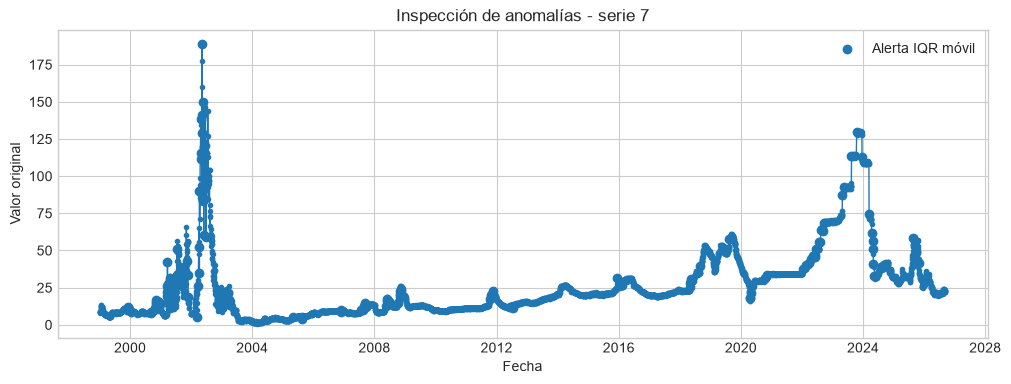

In [11]:
if not outliers.empty:
    plot_id = int(outliers.iloc[0]["idVariable"])
    plot_data = outlier_detail[
        outlier_detail["idVariable_num"].eq(plot_id)
    ].sort_values("fecha_dt")

    figure, axis = plt.subplots(figsize=(12, 4))
    axis.plot(
        plot_data["fecha_dt"],
        plot_data["valor_num"],
        marker=".",
        linewidth=1,
    )

    flagged = plot_data[
        plot_data["outlier_iqr_movil"]
    ]

    axis.scatter(
        flagged["fecha_dt"],
        flagged["valor_num"],
        label="Alerta IQR móvil",
    )

    axis.set_title(f"Inspección de anomalías - serie {plot_id}")
    axis.set_xlabel("Fecha")
    axis.set_ylabel("Valor original")
    axis.legend()
    plt.show()
else:
    print("No se detectaron outliers con la regla IQR móvil.")


## 8. Resumen final de calidad y hallazgos

La tabla final reúne indicadores y alertas descriptivas. No produce un score único de calidad.


In [12]:
duplicate_by_series = (
    history_raw.groupby(["idVariable", "fecha"], dropna=False).size().sub(1).clip(lower=0)
    .groupby(level=0).sum().rename("n_duplicados").reset_index()
)

summary_final = completeness.merge(
    coverage[["idVariable", "periodicidad_declarada", "periodicidad_observada", "periodos_esperados_aprox", "periodos_observados", "n_gaps", "primer_fecha_coincide", "ultima_fecha_coincide"]],
    on="idVariable", how="left",
).merge(
    freshness[["idVariable", "frescura_status", "catalogo_indica_fecha_no_extraida"]],
    on="idVariable", how="left",
).merge(
    metadata_check[["idVariable", "metadata_completa", "nombre_corto_consistente", "metodologia_disponible"]],
    on="idVariable", how="left",
).merge(duplicate_by_series, on="idVariable", how="left")

summary_final["n_duplicados"] = summary_final["n_duplicados"].fillna(0).astype(int)
outlier_counts = (
    outlier_detail.groupby("idVariable_num")["outlier_iqr_movil"]
    .sum()
    .rename("n_outliers_movil")
)
summary_final = summary_final.join(outlier_counts, on="idVariable")
summary_final["n_outliers_movil"] = summary_final["n_outliers_movil"].fillna(0).astype(int)


KNOWN_GAP_EXCEPTIONS = {
    1215: "Gap metodológico documentado mayo-2020 / julio-2022",
}

KNOWN_CONSTANT_EXCEPTIONS = {
    1199: "Tramo pre-cobertura estadística anterior a junio de 1993",
}


def build_flags(row):
    flags = []
    variable_id = int(row["idVariable"])

    if row["n_observaciones"] == 0:
        flags.append("SIN_DATOS")
    if row["n_nulos"] > 0:
        flags.append("NULOS")
    if row["n_duplicados"] > 0:
        flags.append("DUPLICADOS")

    # Gaps conocidos y documentados no se mantienen como alerta abierta.
    if row["n_gaps"] > 0 and variable_id not in KNOWN_GAP_EXCEPTIONS:
        flags.append("GAPS_CANDIDATOS")

    # Tramos constantes ya explicados metodológicamente no quedan como alerta abierta.
    if row["alerta_tramo_constante"] and variable_id not in KNOWN_CONSTANT_EXCEPTIONS:
        flags.append("TRAMO_CONSTANTE")

    # Inflación negativa puede representar deflación válida.
    if row["n_negativos"] > 0 and variable_id not in {27, 28}:
        flags.append("NEGATIVOS")

    # Los outliers IQR nominales se conservan como diagnóstico exploratorio,
    # pero no forman parte del quality flag hasta trabajar con stocks deflactados.

    if not row["metadata_completa"]:
        flags.append("METADATA_INCOMPLETA")
    if not row["primer_fecha_coincide"]:
        flags.append("PRIMERA_FECHA_DIFERENTE")
    if not row["ultima_fecha_coincide"]:
        flags.append("ULTIMA_FECHA_DIFERENTE")
    if row["frescura_status"] not in {"OK_DIARIA", "OK_REZAGO_MENSUAL"}:
        flags.append(row["frescura_status"])

    return "; ".join(flags) if flags else "SIN_ALERTAS"


summary_final["quality_flags"] = summary_final.apply(build_flags, axis=1)

summary_final["known_quality_exception"] = summary_final["idVariable"].map({
    **KNOWN_GAP_EXCEPTIONS,
    **KNOWN_CONSTANT_EXCEPTIONS,
    27: "Valores negativos validados como deflación posible",
    28: "Valores negativos validados como deflación posible",
}).fillna("")
summary_final = summary_final[[
    "idVariable", "nombre_corto", "n_observaciones", "fecha_min", "fecha_max",
    "periodicidad_declarada", "periodicidad_observada", "n_nulos", "pct_nulos",
    "n_duplicados", "n_gaps", "n_ceros", "n_negativos", "n_outliers_movil",
    "metadata_completa", "frescura_status", "known_quality_exception", "quality_flags",
]].sort_values("idVariable")
summary_final


,idVariable,nombre_corto,n_observaciones,fecha_min,fecha_max,periodicidad_declarada,periodicidad_observada,n_nulos,pct_nulos,n_duplicados,n_gaps,n_ceros,n_negativos,n_outliers_movil,metadata_completa,frescura_status,known_quality_exception,quality_flags
0,7,tasa_badlar_privados,6758,1999-01-04,2026-09-10,D,D,0,0.0,0,83,0,0,141,True,OK_DIARIA,,GAPS_CANDIDATOS
1,14,tasa_prestamos_personales,3940,2010-07-01,2026-09-10,D,D,0,0.0,0,18,0,0,37,True,OK_DIARIA,,GAPS_CANDIDATOS
2,27,inflacion_mensual,1002,1943-03-31,2026-08-31,M,M,0,0.0,0,0,26,116,49,True,OK_REZAGO_MENSUAL,Valores negativos validados como deflación pos...,SIN_ALERTAS
3,28,inflacion_interanual,992,1944-01-31,2026-08-31,M,M,0,0.0,0,0,2,53,44,True,OK_REZAGO_MENSUAL,Valores negativos validados como deflación pos...,SIN_ALERTAS
4,135,tasa_tamar,468,2024-10-01,2026-09-10,D,D,0,0.0,0,5,0,0,6,True,OK_DIARIA,,GAPS_CANDIDATOS
5,145,tasa_adelantos_empresas_privadas_1_7_dias,4308,2009-01-02,2026-09-10,D,D,0,0.0,0,21,0,0,195,True,OK_DIARIA,,GAPS_CANDIDATOS
6,883,prestamos_personas_humanas,319,1999-12-31,2026-06-30,M,M,0,0.0,0,0,0,0,5,True,OK_REZAGO_MENSUAL,,SIN_ALERTAS
7,885,prestamos_prestadoras_servicios_financieros,319,1999-12-31,2026-06-30,M,M,0,0.0,0,0,0,0,31,True,OK_REZAGO_MENSUAL,,SIN_ALERTAS
8,891,prestamos_pymes,319,1999-12-31,2026-06-30,M,M,0,0.0,0,0,0,0,9,True,OK_REZAGO_MENSUAL,,SIN_ALERTAS
9,892,prestamos_empresas_no_pymes,319,1999-12-31,2026-06-30,M,M,0,0.0,0,0,0,0,6,True,OK_REZAGO_MENSUAL,,SIN_ALERTAS


### Hallazgos para revisar

La siguiente celda lista automáticamente sólo las series con alertas descriptivas. Una alerta no implica por sí sola un error de datos.


In [13]:
review_findings = summary_final.loc[summary_final["quality_flags"] != "SIN_ALERTAS", ["idVariable", "nombre_corto", "quality_flags"]]
if review_findings.empty:
    display(pd.DataFrame({"hallazgo": ["No se detectaron alertas descriptivas con las reglas actuales."]}))
else:
    display(review_findings)

print("La notebook no modifica ningun dataset y no realiza reconciliaciones matematicas entre series.")


,idVariable,nombre_corto,quality_flags
0,7,tasa_badlar_privados,GAPS_CANDIDATOS
1,14,tasa_prestamos_personales,GAPS_CANDIDATOS
4,135,tasa_tamar,GAPS_CANDIDATOS
5,145,tasa_adelantos_empresas_privadas_1_7_dias,GAPS_CANDIDATOS
11,929,hipotecarios_ml_prestadoras_servicios_financieros,TRAMO_CONSTANTE
15,940,hipotecarios_me_prestadoras_servicios_financieros,TRAMO_CONSTANTE
19,962,prendarios_ml_prestadoras_servicios_financieros,TRAMO_CONSTANTE
22,971,prendarios_me_personas_humanas,TRAMO_CONSTANTE
23,973,prendarios_me_prestadoras_servicios_financieros,TRAMO_CONSTANTE
34,1153,hipotecarios_me_ph_construccion,TRAMO_CONSTANTE


La notebook no modifica ningun dataset y no realiza reconciliaciones matematicas entre series.


## 9. Profundización de los grupos de alertas

Esta sección no agrega nuevas reglas de calidad. Profundiza las alertas ya detectadas para poder inspeccionarlas antes de decidir si representan un problema real.

Se revisan por separado:

1. **gaps temporales**;
2. **ceros y tramos constantes**;
3. **outliers IQR sobre la variación porcentual**.

Las tablas son diagnósticas. Ninguna observación se modifica, elimina o imputa.


In [14]:
# Resumen de alertas por grupo
alert_group_summary = pd.DataFrame([
    {
        "grupo_alerta": "Gaps candidatos",
        "n_series": int((summary_final["n_gaps"] > 0).sum()),
        "n_eventos": int(summary_final["n_gaps"].sum()),
    },
    {
        "grupo_alerta": "Tramos constantes",
        "n_series": int(completeness["alerta_tramo_constante"].sum()),
        "n_eventos": np.nan,
    },
    {
        "grupo_alerta": "Series con ceros",
        "n_series": int((summary_final["n_ceros"] > 0).sum()),
        "n_eventos": int(summary_final["n_ceros"].sum()),
    },
    {
        "grupo_alerta": "Outliers IQR móvil",
        "n_series": int((summary_final["n_outliers_movil"] > 0).sum()),
        "n_eventos": int(summary_final["n_outliers_movil"].sum()),
    },
])

display(alert_group_summary)


,grupo_alerta,n_series,n_eventos
0,Gaps candidatos,6,184.0
1,Tramos constantes,23,NaN
2,Series con ceros,24,3840.0
3,Outliers IQR móvil,65,1604.0


### 9.1 Gaps temporales

Para series mensuales se identifican meses ausentes entre la primera y última observación.

Para series diarias se utilizan **días hábiles bancarios BCRA**.

Este criterio reemplaza dos aproximaciones previas:

- lunes a viernes (`bdate_range`);
- lunes a viernes excluyendo feriados nacionales argentinos.

Ambas generaban falsos positivos porque un **día hábil civil no necesariamente es un día hábil bancario**. El cambio se realizó después de observar que varios gaps candidatos coincidían con jornadas sin actividad bancaria.

El calendario actual combina:

- feriados nacionales argentinos;
- cierres/no laborables bancarios documentados por el BCRA;
- Día del Bancario;
- cierres históricos adicionales incorporados explícitamente en la notebook.

**Fuente principal:**  
BCRA — Feriados bancarios  
https://www.bcra.gob.ar/consulta-feriados-bancarios/

**Referencia metodológica:**  
BCRA — SISCEN  
https://www.bcra.gob.ar/archivos/Pdfs/PublicacionesEstadisticas/siscen.pdf

> Los gaps que sobreviven a este filtro siguen siendo **candidatos a revisión**. No se imputan ni se clasifican automáticamente como errores.


In [15]:
def build_gap_detail(history_df, catalog_df):
    rows = []

    for variable_id, group in history_df.groupby("idVariable_num", dropna=True):
        variable_id = int(variable_id)
        group = group.sort_values("fecha_dt").copy()
        dates = pd.DatetimeIndex(group["fecha_dt"].dropna().unique()).sort_values()

        metadata_row = catalog_df.loc[catalog_df["idVariable"].eq(variable_id)]
        declared = metadata_row["periodicidad"].iloc[0] if not metadata_row.empty else None
        nombre = group["nombre_corto"].dropna().iloc[0] if group["nombre_corto"].notna().any() else None

        if len(dates) < 2:
            continue

        if declared == "M":
            observed = set(pd.PeriodIndex(dates, freq="M"))
            expected = pd.period_range(min(observed), max(observed), freq="M")
            missing = sorted(set(expected) - observed)

            for period in missing:
                missing_date = period.to_timestamp("M")
                previous_dates = dates[dates < missing_date]
                next_dates = dates[dates > missing_date]
                rows.append({
                    "idVariable": variable_id,
                    "nombre_corto": nombre,
                    "periodicidad": declared,
                    "gap": str(period),
                    "tipo_gap": "MES_FALTANTE",
                    "fecha_anterior": previous_dates.max() if len(previous_dates) else pd.NaT,
                    "fecha_siguiente": next_dates.min() if len(next_dates) else pd.NaT,
                })

        elif declared == "D":
            expected = bcra_bank_business_days(dates.min(), dates.max())
            missing = sorted(set(expected) - set(dates.normalize()))

            for missing_date in missing:
                previous_dates = dates[dates < missing_date]
                next_dates = dates[dates > missing_date]
                rows.append({
                    "idVariable": variable_id,
                    "nombre_corto": nombre,
                    "periodicidad": declared,
                    "gap": pd.Timestamp(missing_date).date().isoformat(),
                    "tipo_gap": "DIA_HABIL_BANCARIO_CANDIDATO",
                    "fecha_anterior": previous_dates.max() if len(previous_dates) else pd.NaT,
                    "fecha_siguiente": next_dates.min() if len(next_dates) else pd.NaT,
                })

    return pd.DataFrame(rows)


gap_detail = build_gap_detail(history, selected_catalog)

if gap_detail.empty:
    display(pd.DataFrame({"resultado": ["No se detectaron gaps candidatos."]}))
else:
    gap_summary = (
        gap_detail.groupby(
            ["idVariable", "nombre_corto", "periodicidad", "tipo_gap"],
            dropna=False,
        )
        .size()
        .rename("n_gaps")
        .reset_index()
        .sort_values(["n_gaps", "idVariable"], ascending=[False, True])
    )

    display(gap_summary)
    display(gap_detail.sort_values(["idVariable", "gap"]).head(200))


,idVariable,nombre_corto,periodicidad,tipo_gap,n_gaps
0,7,tasa_badlar_privados,D,DIA_HABIL_BANCARIO_CANDIDATO,83
4,1189,tasa_plazo_fijo_pesos,D,DIA_HABIL_BANCARIO_CANDIDATO,30
5,1215,tasa_financiaciones_tarjetas,M,MES_FALTANTE,27
3,145,tasa_adelantos_empresas_privadas_1_7_dias,D,DIA_HABIL_BANCARIO_CANDIDATO,21
1,14,tasa_prestamos_personales,D,DIA_HABIL_BANCARIO_CANDIDATO,18
2,135,tasa_tamar,D,DIA_HABIL_BANCARIO_CANDIDATO,5


,idVariable,nombre_corto,periodicidad,gap,tipo_gap,fecha_anterior,fecha_siguiente
0,7,tasa_badlar_privados,D,1999-04-01,DIA_HABIL_BANCARIO_CANDIDATO,1999-03-31,1999-04-05
1,7,tasa_badlar_privados,D,1999-12-31,DIA_HABIL_BANCARIO_CANDIDATO,1999-12-30,2000-01-03
2,7,tasa_badlar_privados,D,2000-04-20,DIA_HABIL_BANCARIO_CANDIDATO,2000-04-19,2000-04-24
3,7,tasa_badlar_privados,D,2000-12-29,DIA_HABIL_BANCARIO_CANDIDATO,2000-12-28,2001-01-02
4,7,tasa_badlar_privados,D,2001-04-12,DIA_HABIL_BANCARIO_CANDIDATO,2001-04-11,2001-04-16
...,...,...,...,...,...,...,...
179,1215,tasa_financiaciones_tarjetas,M,2022-03,MES_FALTANTE,2020-04-30,2022-08-31
180,1215,tasa_financiaciones_tarjetas,M,2022-04,MES_FALTANTE,2020-04-30,2022-08-31
181,1215,tasa_financiaciones_tarjetas,M,2022-05,MES_FALTANTE,2020-04-30,2022-08-31
182,1215,tasa_financiaciones_tarjetas,M,2022-06,MES_FALTANTE,2020-04-30,2022-08-31


### Hallazgo de calidad — Serie 1215: tasa de financiaciones con tarjetas de crédito

Durante el EDA se detectaron **27 meses faltantes** en la serie `1215`, concentrados entre 2020 y 2022.

Para determinar si se trataba de un problema de extracción o de un faltante legítimo de la fuente, se contrastó la serie API con archivos históricos oficiales del BCRA (`pre2019`, `pre2020`, `pre2021`, `pre2022` y `pre2023`).

La documentación metodológica y los archivos históricos muestran que, a partir de **mayo de 2020**, cambia el tratamiento estadístico de las financiaciones con tarjetas de crédito por la inclusión de operaciones asociadas a los **Créditos a Tasa Cero** (Comunicaciones `A 6993` y `A 7082`).

En los archivos históricos se observa que:

- hasta abril de 2020 la tasa total de tarjetas presenta datos;
- entre mayo de 2020 y 2022 el agregado total deja de publicarse de forma continua;
- durante ese período continúa disponible la categoría de financiaciones **a tasa de interés distinta de cero**;
- posteriormente la serie total vuelve a publicarse.

Por lo tanto, los faltantes de `1215` no se interpretan como un error del proceso de extracción ni como valores que deban ser imputados.

**Clasificación:** `LEGITIMATE_GAP / METHODOLOGY_CHANGE`

**Decisión de calidad:**
- conservar los faltantes como `NaN`;
- no interpolar ni reconstruir `1215`;
- no reemplazar `1215` por otra serie;
- utilizar `1220` —financiaciones con tasa distinta de cero— como serie complementaria durante el análisis;
- documentar el cambio metodológico como parte del diccionario de datos.

Este hallazgo queda cerrado como una discontinuidad metodológica documentada de la fuente oficial.


### Aclaración confirmada — TAMAR (`135`) y cambio metodológico en 2026

La serie TAMAR es diaria y presenta un **cambio metodológico documentado a partir de 2026**, cuando el BCRA pasa a calcularla utilizando el nuevo requerimiento informativo SISCEN 19.

Este cambio de fuente/metodología debe tratarse como un **breakpoint metodológico**, no como un error de datos.

**Decisión de calidad:**
- conservar la serie;
- no corregir ni empalmar artificialmente los valores;
- documentar 2026 como cambio metodológico;
- evaluar los gaps diarios únicamente contra el calendario bancario BCRA.


### 9.2 Ceros y tramos constantes

Se inspeccionan secuencias consecutivas con el mismo valor.

El objetivo es distinguir entre:

- ceros aislados;
- períodos prolongados en cero;
- valores no nulos que permanecen constantes durante muchos períodos.

Un tramo constante puede ser legítimo. Esta sección sólo identifica dónde ocurre.


In [16]:
def constant_run_table(history_df, catalog_df):
    runs = []

    for variable_id, group in history_df.groupby("idVariable_num", dropna=True):
        variable_id = int(variable_id)
        group = group.sort_values("fecha_dt").copy()
        group = group[group["valor_num"].notna()].copy()

        if group.empty:
            continue

        metadata_row = catalog_df.loc[catalog_df["idVariable"].eq(variable_id)]
        declared = metadata_row["periodicidad"].iloc[0] if not metadata_row.empty else None
        nombre = group["nombre_corto"].dropna().iloc[0] if group["nombre_corto"].notna().any() else None

        change_group = group["valor_num"].ne(group["valor_num"].shift()).cumsum()

        for _, run in group.groupby(change_group):
            runs.append({
                "idVariable": variable_id,
                "nombre_corto": nombre,
                "periodicidad": declared,
                "valor": run["valor_num"].iloc[0],
                "fecha_inicio": run["fecha_dt"].min(),
                "fecha_fin": run["fecha_dt"].max(),
                "n_observaciones": len(run),
                "duracion_dias": (run["fecha_dt"].max() - run["fecha_dt"].min()).days,
                "es_cero": bool(run["valor_num"].iloc[0] == 0),
            })

    runs_df = pd.DataFrame(runs)
    if runs_df.empty:
        return runs_df

    runs_df["umbral_alerta"] = np.where(runs_df["periodicidad"].eq("D"), 30, 12)
    runs_df["tramo_constante_alerta"] = runs_df["n_observaciones"] >= runs_df["umbral_alerta"]
    return runs_df


constant_runs = constant_run_table(history, selected_catalog)

if constant_runs.empty:
    display(pd.DataFrame({"resultado": ["No se pudieron construir tramos constantes."]}))
else:
    constant_alerts = constant_runs.loc[
        constant_runs["tramo_constante_alerta"]
    ].sort_values(
        ["n_observaciones", "idVariable"],
        ascending=[False, True],
    )

    zero_runs = constant_runs.loc[
        constant_runs["es_cero"]
    ].sort_values(
        ["n_observaciones", "idVariable"],
        ascending=[False, True],
    )

    print("Tramos constantes que superan el umbral:")
    display(constant_alerts.head(100))

    print("Principales tramos consecutivos en cero:")
    display(zero_runs.head(100))


Tramos constantes que superan el umbral:


,idVariable,nombre_corto,periodicidad,valor,fecha_inicio,fecha_fin,n_observaciones,duracion_dias,es_cero,umbral_alerta,tramo_constante_alerta
19258,940,hipotecarios_me_prestadoras_servicios_financieros,M,0.0,2001-05-31,2026-06-30,302,9161,True,12,True
26987,1178,hipotecarios_me_pj_refaccion,M,0.0,2002-01-31,2026-06-30,294,8916,True,12,True
21202,973,prendarios_me_prestadoras_servicios_financieros,M,0.0,1999-12-31,2024-04-30,293,8887,True,12,True
27001,1179,hipotecarios_me_pj_compra_nuevas,M,0.0,2002-02-28,2026-06-30,293,8888,True,12,True
24291,1153,hipotecarios_me_ph_construccion,M,0.0,2002-03-31,2026-06-30,292,8857,True,12,True
26979,1177,hipotecarios_me_pj_construccion,M,0.0,2004-06-30,2026-06-30,265,8035,True,12,True
27044,1180,hipotecarios_me_pj_compra_usadas,M,0.0,2009-08-31,2026-06-30,203,6147,True,12,True
24323,1154,hipotecarios_me_ph_refaccion,M,0.0,2012-08-31,2026-06-30,167,5051,True,12,True
25526,1170,hipotecarios_ml_pj_refaccion,M,0.0,2014-12-31,2026-06-30,139,4199,True,12,True
25572,1171,hipotecarios_ml_pj_compra_nuevas,M,0.0,2014-12-31,2026-06-30,139,4199,True,12,True


Principales tramos consecutivos en cero:


,idVariable,nombre_corto,periodicidad,valor,fecha_inicio,fecha_fin,n_observaciones,duracion_dias,es_cero,umbral_alerta,tramo_constante_alerta
19258,940,hipotecarios_me_prestadoras_servicios_financieros,M,0.0,2001-05-31,2026-06-30,302,9161,True,12,True
26987,1178,hipotecarios_me_pj_refaccion,M,0.0,2002-01-31,2026-06-30,294,8916,True,12,True
21202,973,prendarios_me_prestadoras_servicios_financieros,M,0.0,1999-12-31,2024-04-30,293,8887,True,12,True
27001,1179,hipotecarios_me_pj_compra_nuevas,M,0.0,2002-02-28,2026-06-30,293,8888,True,12,True
24291,1153,hipotecarios_me_ph_construccion,M,0.0,2002-03-31,2026-06-30,292,8857,True,12,True
26979,1177,hipotecarios_me_pj_construccion,M,0.0,2004-06-30,2026-06-30,265,8035,True,12,True
27044,1180,hipotecarios_me_pj_compra_usadas,M,0.0,2009-08-31,2026-06-30,203,6147,True,12,True
24323,1154,hipotecarios_me_ph_refaccion,M,0.0,2012-08-31,2026-06-30,167,5051,True,12,True
25526,1170,hipotecarios_ml_pj_refaccion,M,0.0,2014-12-31,2026-06-30,139,4199,True,12,True
25572,1171,hipotecarios_ml_pj_compra_nuevas,M,0.0,2014-12-31,2026-06-30,139,4199,True,12,True


### Hallazgo confirmado — Serie 1199: ceros anteriores a la cobertura estadística

La serie `1199` —adelantos en cuenta corriente a tasa fija— presenta aproximadamente **41 observaciones consecutivas en cero entre enero de 1990 y mayo de 1993**.

La documentación histórica del BCRA ubica el comienzo de publicación de esta familia estadística en **junio de 1993**. Por lo tanto, esos ceros anteriores no deben interpretarse como una tasa económica efectiva de 0%, sino como un tramo **previo a la cobertura estadística**.

**Clasificación:** `PRE_COBERTURA_ESTADISTICA`

**Decisión de calidad:**
- conservar intacto el dato en la capa `raw`;
- en una capa procesada/analítica, tratar `1199` anterior a junio de 1993 como `NaN`;
- no imputar ni interpolar;
- no considerar este tramo un error de extracción.


In [17]:
# constant_alerts.reset_index().set_index("idVariable").index.unique()
# .loc[1215].head(5)


### 9.3 Outliers IQR móvil: concentración y contexto

El flag se calcula exclusivamente con **IQR móvil** sobre la métrica de cambio correspondiente:

- tasas e inflación: diferencia en puntos porcentuales;
- stocks y saldos: variación porcentual respecto del período anterior.

La ventana se adapta a la periodicidad y utiliza sólo información previa a la observación evaluada.

En esta sección se inspecciona:

- qué series concentran más alertas móviles;
- qué proporción de observaciones queda marcada;
- cuáles son los movimientos más extremos según su propia unidad de análisis.

El flag es una señal exploratoria y no implica automáticamente un error de datos.


In [18]:
outlier_summary = (
    outlier_detail.groupby(["idVariable_num", "nombre_corto"], dropna=False)
    .agg(
        n_observaciones=("fecha_dt", "size"),
        n_outliers_movil=("outlier_iqr_movil", "sum"),
        max_variacion_analisis=("variacion_analisis", "max"),
        min_variacion_analisis=("variacion_analisis", "min"),
        tipo_variacion=("tipo_variacion", "first"),
    )
    .reset_index()
    .rename(columns={"idVariable_num": "idVariable"})
)

outlier_summary["pct_outliers_movil"] = (
    outlier_summary["n_outliers_movil"] / outlier_summary["n_observaciones"] * 100
)
outlier_summary = outlier_summary.sort_values(
    ["pct_outliers_movil", "n_outliers_movil"],
    ascending=[False, False],
)

display(outlier_summary)

print("Movimientos extremos marcados por IQR móvil:")
display(
    outliers.assign(abs_variacion_analisis=outliers["variacion_analisis"].abs())
    .sort_values("abs_variacion_analisis", ascending=False)
    .drop(columns="abs_variacion_analisis")
    .head(100)
)


,idVariable,nombre_corto,n_observaciones,n_outliers_movil,max_variacion_analisis,min_variacion_analisis,tipo_variacion,pct_outliers_movil
19,962,prendarios_ml_prestadoras_servicios_financieros,319,44,271.761658,-100.000000,porcentual,13.793103
41,1160,prendarios_me_ph_otros,319,41,1900.000000,-100.000000,porcentual,12.852665
26,1145,hipotecarios_ml_ph_construccion,319,39,499.346405,-42.736077,porcentual,12.225705
27,1146,hipotecarios_ml_ph_refaccion,319,37,152.054795,-56.956522,porcentual,11.598746
25,980,prendarios_me_empresas_no_pymes,319,35,600.000000,-87.690840,porcentual,10.971787
57,1184,prendarios_me_pj_otros,319,33,1025.000000,-91.339648,porcentual,10.344828
7,885,prestamos_prestadoras_servicios_financieros,319,31,733.333333,-85.074627,porcentual,9.717868
11,929,hipotecarios_ml_prestadoras_servicios_financieros,319,30,366.666667,-100.000000,porcentual,9.404389
22,971,prendarios_me_personas_humanas,319,30,300.000000,-96.586134,porcentual,9.404389
28,1147,hipotecarios_ml_ph_compra_nuevas,319,30,305.813953,-42.838710,porcentual,9.404389


Movimientos extremos marcados por IQR móvil:


,idVariable,nombre_corto,fecha,valor,valor_anterior,variacion,variacion_analisis,tipo_variacion,outlier_iqr_movil,iqr_movil_lower,iqr_movil_upper
12254,28,inflacion_interanual,1990-03-31,20262.8,12085.4,8177.4,8177.400000,puntos_porcentuales,True,-4189.000000,5641.800000
30891,1175,prendarios_ml_pj_maquinarias,2002-01-31,134.0,2.0,132.0,6600.000000,porcentual,True,-20.000000,15.000000
12253,28,inflacion_interanual,1990-02-28,12085.4,8165.2,3920.2,3920.200000,puntos_porcentuales,True,-2460.400000,3295.000000
28293,1158,prendarios_me_ph_automotores,2024-10-31,78705.0,2293.0,76412.0,3332.402966,porcentual,True,-18.770263,33.252070
25787,1151,prendarios_ml_ph_maquinarias,2002-01-31,101.0,3.0,98.0,3266.666667,porcentual,True,-37.500000,50.000000
12252,28,inflacion_interanual,1990-01-31,8165.2,4923.6,3241.6,3241.600000,puntos_porcentuales,True,-1220.500000,1623.950000
21959,968,prendarios_ml_pymes,2002-01-31,446.0,17.0,429.0,2523.529412,porcentual,True,-20.168067,15.126050
33397,1182,prendarios_me_pj_automotores,2024-10-31,87590.0,3582.0,84008.0,2345.281965,porcentual,True,-17.877459,38.360343
21321,960,prendarios_ml_personas_humanas,2002-01-31,1643.0,69.0,1574.0,2281.159420,porcentual,True,-17.623183,7.851135
25468,1150,prendarios_ml_ph_automotores,2002-01-31,998.0,43.0,955.0,2220.930233,porcentual,True,-16.298003,4.508449


### Aclaración metodológica — outliers en stocks nominales argentinos

Los outliers detectados mediante IQR móvil se conservan como **señales exploratorias**, pero dejan de formar parte de `quality_flags`.

En series monetarias argentinas de largo plazo, la combinación de:

- inflación elevada;
- cambios de régimen;
- shocks macroeconómicos;
- denominadores pequeños;

puede generar variaciones porcentuales extremas sin que exista un error de calidad.

**Decisión actual:**
- conservar `n_outliers_movil` y el explorador Plotly como herramientas diagnósticas;
- no eliminar, winsorizar ni corregir observaciones por IQR;
- no marcar una serie como problema de calidad únicamente por contener outliers;
- volver a evaluar anomalías cuando los stocks hayan sido **deflactados por inflación**.


## 10. Explorador Plotly — serie + IQR móvil

Este módulo permite inspeccionar una serie y observar:

1. el nivel de la serie;
2. las observaciones marcadas por IQR móvil;
3. la métrica de cambio correspondiente:
   - puntos porcentuales para tasas e inflación;
   - variación porcentual para stocks/saldos;
4. los límites móviles inferior y superior a lo largo del tiempo.

El IQR móvil utiliza exclusivamente información pasada:

- 90 observaciones para series diarias, mínimo 30;
- 12 observaciones para series mensuales, mínimo 6.

La observación actual no influye en sus propios límites porque la ventana se calcula sobre datos hasta `t-1`.

El gráfico es únicamente de inspección de calidad. No elimina, corrige ni imputa observaciones.


In [19]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots


def plot_series_iqr(variable_id, show=True):
    variable_id = int(variable_id)

    group = (
        outlier_detail.loc[
            outlier_detail["idVariable_num"].eq(variable_id)
        ]
        .sort_values("fecha_dt")
        .copy()
    )

    if group.empty:
        raise ValueError(f"No hay datos para idVariable={variable_id}")

    nombre = (
        group["nombre_corto"].dropna().iloc[0]
        if group["nombre_corto"].notna().any()
        else str(variable_id)
    )

    tipo_variacion = group["tipo_variacion"].dropna().iloc[0]

    variacion_label = (
        "Cambio en puntos porcentuales"
        if tipo_variacion == "puntos_porcentuales"
        else "Variación porcentual"
    )
    variacion_format = (
        "pp"
        if tipo_variacion == "puntos_porcentuales"
        else "%"
    )

    fig = make_subplots(
        rows=2,
        cols=1,
        shared_xaxes=True,
        vertical_spacing=0.08,
        subplot_titles=(
            "Valor de la serie y outliers IQR móvil",
            f"{variacion_label} y límites IQR móviles",
        ),
    )

    # Serie original
    fig.add_trace(
        go.Scatter(
            x=group["fecha_dt"],
            y=group["valor_num"],
            mode="lines",
            name="Valor",
            hovertemplate=(
                "Fecha=%{x|%Y-%m-%d}<br>"
                "Valor=%{y}<extra></extra>"
            ),
        ),
        row=1,
        col=1,
    )

    # Outliers móviles
    flagged = group.loc[group["outlier_iqr_movil"]]

    if not flagged.empty:
        fig.add_trace(
            go.Scatter(
                x=flagged["fecha_dt"],
                y=flagged["valor_num"],
                mode="markers",
                name="Outlier IQR móvil",
                marker={"size": 8},
                customdata=flagged[["variacion_analisis"]],
                hovertemplate=(
                    "Fecha=%{x|%Y-%m-%d}<br>"
                    "Valor=%{y}<br>"
                    f"{variacion_label}=%{{customdata[0]:.2f}} "
                    f"{variacion_format}<extra></extra>"
                ),
            ),
            row=1,
            col=1,
        )

    # Variación analizada
    fig.add_trace(
        go.Scatter(
            x=group["fecha_dt"],
            y=group["variacion_analisis"],
            mode="lines+markers",
            name=variacion_label,
            hovertemplate=(
                "Fecha=%{x|%Y-%m-%d}<br>"
                f"{variacion_label}=%{{y:.2f}} "
                f"{variacion_format}<extra></extra>"
            ),
        ),
        row=2,
        col=1,
    )

    # Límite móvil inferior
    fig.add_trace(
        go.Scatter(
            x=group["fecha_dt"],
            y=group["iqr_movil_lower"],
            mode="lines",
            name="Límite móvil inferior",
            line={"dash": "dot"},
            hovertemplate=(
                "Fecha=%{x|%Y-%m-%d}<br>"
                f"Límite inferior=%{{y:.2f}} "
                f"{variacion_format}<extra></extra>"
            ),
        ),
        row=2,
        col=1,
    )

    # Límite móvil superior
    fig.add_trace(
        go.Scatter(
            x=group["fecha_dt"],
            y=group["iqr_movil_upper"],
            mode="lines",
            name="Límite móvil superior",
            line={"dash": "dot"},
            hovertemplate=(
                "Fecha=%{x|%Y-%m-%d}<br>"
                f"Límite superior=%{{y:.2f}} "
                f"{variacion_format}<extra></extra>"
            ),
        ),
        row=2,
        col=1,
    )

    fig.update_layout(
        title=f"{variable_id} — {nombre}",
        height=750,
        hovermode="x unified",
        legend_title_text="Serie",
    )

    fig.update_yaxes(
        title_text="Valor",
        row=1,
        col=1,
    )

    fig.update_yaxes(
        title_text=f"{variacion_label} ({variacion_format})",
        row=2,
        col=1,
    )

    fig.update_xaxes(
        title_text="Fecha",
        row=2,
        col=1,
    )

    if show:
        fig.show()

    return fig


series_selector_table = (
    selected_catalog.loc[
        selected_catalog["idVariable"].isin(EXPECTED_IDS),
        [
            "idVariable",
            "nombre_corto",
            "descripcion",
            "periodicidad",
            "moneda",
        ],
    ]
    .sort_values("idVariable")
    .reset_index(drop=True)
)

display(series_selector_table)


,idVariable,nombre_corto,descripcion,periodicidad,moneda
0,7,tasa_badlar_privados,Tasa de interés BADLAR de bancos privados,D,ML
1,14,tasa_prestamos_personales,Tasa de interés de préstamos personales,D,ML
2,27,inflacion_mensual,Inflación mensual.,M,ML
3,28,inflacion_interanual,Inflación interanual.,M,ML
4,135,tasa_tamar,Tasa de interés TAMAR de bancos públicos y pri...,D,ML
5,145,tasa_adelantos_empresas_privadas_1_7_dias,Tasa de interés de adelantos en cuenta corrien...,D,ML
6,883,prestamos_personas_humanas,Total de préstamos a personas humanas,M,MEyML
7,885,prestamos_prestadoras_servicios_financieros,Total de préstamos a las prestadoras de servic...,M,MEyML
8,891,prestamos_pymes,Total de préstamos a pequeños y medianos empre...,M,MEyML
9,892,prestamos_empresas_no_pymes,Total de préstamos a las empresas no constitui...,M,MEyML


In [20]:
import plotly.io as pio
pio.renderers.default = "browser"


In [21]:
SERIE = 28
plot_series_iqr(SERIE)


## Reconciliaciones entre series

Esta notebook describe cuatro familias de reconciliación: personas jurídicas,
hipotecarios ML + ME, destinos ML + ME y suma de destinos contra totales hipotecarios.
No las ejecuta automáticamente. La herramienta opcional `04_reconcile_base_a.py`
se conserva en el ZIP histórico, en `archivo_obsoleto/simplificacion/herramientas/`.
No es una dependencia del pipeline operativo. Los hallazgos históricos se mantienen aquí.
